# Pre-entrega 3 · Clasificador supervisado con TF-IDF (AG News)
**Data Science III · Módulo 3** — Elizabeth Luque

Pipeline completo **texto crudo → preprocesamiento (Módulo 2) → TF-IDF → clasificador → evaluación**, sobre el mismo corpus de los módulos anteriores.

| # | Sección |
|---|---|
| 0 | Setup |
| 1 | Carga con el loader de la cátedra y validación de splits |
| 2 | Preprocesamiento reutilizado del Módulo 2 |
| 3 | Diseño anti-leakage y matriz documento-término (BoW vs. TF-IDF) |
| 4 | Experimento 1 · `max_features` × `ngram_range` × modelo (CV de 5 folds sobre train) |
| 5 | Experimento 2 · Regularización de cada modelo |
| 6 | Experimento 3 · Preprocesamiento: crudo vs. stemming (Porter) vs. lematización (Módulo 2) |
| 7 | Experimento 4 · CountVectorizer (BoW) vs. TfidfVectorizer, con 4 modelos (incluye Random Forest) |
| 8 | Modelo final: entrenamiento en train y evaluación única en test |
| 9 | Matriz de confusión y análisis de errores |
| 10 | Métricas para texto: F1 macro / weighted / micro y curvas Precision-Recall |
| 11 | Interpretabilidad: términos con más peso por clase |
| 12 | Uso del modelo: guardar, cargar y predecir titulares nuevos |
| 13 | Exploración no supervisada: tópicos con LDA vs. categorías reales |
| 14 | Tabla esperado vs. observado y conclusiones |

**Regla de evaluación:** todas las decisiones (modelo, vectorizador, hiperparámetros) se toman con **validación cruzada dentro de train**. El **test se usa una sola vez**, en la sección 7.

## 0. Setup
En Colab: clonar el repo y ejecutar `pip install -r requirements.txt` y `python -m spacy download en_core_web_sm`.

In [1]:
# !git clone https://github.com/scarletluque0805/ds3-clasificador-tfidf.git && %cd ds3-clasificador-tfidf
# !pip install -q -r requirements.txt && python -m spacy download en_core_web_sm
# import nltk; nltk.download("stopwords")
import sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn
from src import train_baseline as tb
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 160)
print(f"scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__} | semilla {tb.SEED}")

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3 | semilla 42


## 1. Carga con el loader de la cátedra y validación de splits
Se usa `data/cargar_dataset.py` tal como lo provee la cátedra, con los splits originales `ag_news_train.csv` / `ag_news_test.csv`.

In [2]:
t0 = time.time()
train_df, test_df = tb.cargar_y_preprocesar(usar_cache=False)   # False = se recalcula desde el texto crudo
seg_preproc = time.time() - t0
print(f"Carga + preprocesamiento de {len(train_df) + len(test_df):,} noticias: {seg_preproc:.1f} s")
tb.validar(train_df, test_df)

Carga + preprocesamiento de 10,000 noticias: 22.4 s


,filas,nulos,duplicados,test_en_train,docs_vacios_tras_preproc
train,8000,0,0,—,0
test,2000,0,0,0,0


In [3]:
pd.DataFrame({"train": train_df.label.value_counts(), "test": test_df.label.value_counts()}).sort_index()

,train,test
label,,
Business,2000,500
Sci_Tech,2000,500
Sports,2000,500
World,2000,500


No hay nulos ni duplicados, **ningún texto de test aparece en train** y las clases están perfectamente balanceadas (2.000 / 500 por clase). Por eso usamos **F1-macro** como métrica principal; con clases balanceadas coincide con la accuracy.

## 2. Preprocesamiento reutilizado del Módulo 2
`src/text_preprocessing.py` es el mismo módulo de la Pre-entrega 2:
- **Limpieza regex:** HTML escapado, entidades rotas `#39;`, URLs, firmas de agencia, datelines, tickers.
- **Normalización:** `US` → `U.S.` y minúsculas.
- **Lematización** con spaCy.
- **Stop-words fuera, pero se conservan las negaciones.**

Al TF-IDF le pasamos la columna `text_nostop`.

In [4]:
train_df[["text", "text_nostop", "label"]].sample(3, random_state=7)

,text,text_nostop,label
3641,"SunTrust Restates First-Half Results. NEW YORK (Reuters) - SunTrust Banks Inc. &lt;A HREF=""http://www.investor.reuters.com/FullQuote.aspx?ticker=STI.N targe...",suntrust restate half result suntrust banks inc fire executive accounting bad loan friday restate half profit high 25.1 million forecast fix mistake,Business
5086,"India, Pakistan approve key proposals ahead of ministers #39; meeting. NEW DELHI : Top Indian and Pakistani officials approved proposals to break the impass...",india pakistan approve key proposal ahead minister meeting new delhi indian pakistani official approve proposal break impasse kashmir strengthen tie eve mee...,World
1657,EasyJet faces tough year ahead. An increase in passengers has propped up annual earnings for easyJet but the low-cost airline has warned it faces a tough tw...,easyjet face tough year ahead increase passenger prop annual earning easyjet low cost airline warn face tough year cut throat competition drive fare fuel pr...,Business


## 3. Diseño anti-leakage
El `TfidfVectorizer` va **dentro** de un `sklearn.Pipeline` junto con el clasificador. Así, `pipeline.fit(X_train)` hace `fit_transform` del vectorizador **solo con train**, y `pipeline.predict(X_test)` hace solo `transform`. En la validación cruzada pasa lo mismo en cada fold: el vocabulario y el IDF se aprenden con los 4 folds de entrenamiento y nunca con el fold de validación.

**Parámetros fijos del vectorizador** (los explorados van en el experimento 1):

| Parámetro | Valor | Motivo |
|---|---|---|
| `token_pattern` | `\S+` | el texto ya viene tokenizado por spaCy; respetamos esos tokens (`u.s`, `e-mail`) |
| `lowercase` | `False` | ya está en minúsculas |
| `min_df` | 2 | descarta términos que aparecen en un solo documento (typos, nombres únicos): reduce el ruido y el overfitting |
| `max_df` | 0.95 | descarta términos presentes en más del 95% de los documentos |
| `sublinear_tf` | `True` | usa 1 + log(tf), así una palabra repetida en la misma noticia no domina |
| `norm` | `l2` | proyecta cada documento sobre la hiperesfera unitaria, sin sesgo por longitud |

In [5]:
# Prueba concreta de que no hay fuga: el vocabulario se aprende solo con train
pipe_demo = tb.construir_pipeline("Naive Bayes", None, (1, 2)).fit(train_df.text_nostop, train_df.label)
vocab = pipe_demo.named_steps["tfidf"].vocabulary_
tokens_test = set(t for d in test_df.text_nostop for t in d.split())
tokens_train = set(t for d in train_df.text_nostop for t in d.split())
solo_test = tokens_test - tokens_train
print(f"Términos que aparecen SOLO en test: {len(solo_test):,} (ej.: {sorted(solo_test)[:6]})")
print(f"¿Alguno de ellos quedó en el vocabulario del vectorizador? {sum(t in vocab for t in solo_test)}")
X_te_demo = pipe_demo.named_steps["tfidf"].transform(test_df.text_nostop)
print(f"Matriz de test: {X_te_demo.shape} (mismas columnas que train), formato {type(X_te_demo).__name__}, "
      f"densidad {X_te_demo.nnz / np.prod(X_te_demo.shape):.3%}")

Términos que aparecen SOLO en test: 1,943 (ej.: ['-chartered', '-judge', '-ll', '-nathan', '-witnesse', '.99'])
¿Alguno de ellos quedó en el vocabulario del vectorizador? 0
Matriz de test: (2000, 25780) (mismas columnas que train), formato csr_matrix, densidad 0.087%


La matriz es **esparsa** (formato CSR): menos del 0,1% de las celdas son distintas de cero. Por eso scikit-learn la guarda comprimida y no como un array denso.

### Matriz documento-término: BoW vs. TF-IDF en miniatura
Como en el ejemplo de clase ("El Barcelona de Messi es mejor que el Real Madrid de Ronaldo"), vemos qué guarda cada representación con dos titulares que comparten casi todas las palabras pero dicen cosas opuestas.

In [6]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
mini = ["Microsoft beats Google in cloud deal", "Google beats Microsoft in cloud deal, shares of Google jump"]
bow = CountVectorizer(); tfv = TfidfVectorizer()
dtm_bow = pd.DataFrame(bow.fit_transform(mini).toarray(), index=["titular 1", "titular 2"], columns=bow.get_feature_names_out())
dtm_tfidf = pd.DataFrame(tfv.fit_transform(mini).toarray(), index=["titular 1", "titular 2"], columns=tfv.get_feature_names_out()).round(2)
display(dtm_bow); display(dtm_tfidf)

,beats,cloud,deal,google,in,jump,microsoft,of,shares
titular 1,1,1,1,1,1,0,1,0,0
titular 2,1,1,1,2,1,1,1,1,1


,beats,cloud,deal,google,in,jump,microsoft,of,shares
titular 1,0.41,0.41,0.41,0.41,0.41,0.00,0.41,0.00,0.00
titular 2,0.26,0.26,0.26,0.52,0.26,0.36,0.26,0.36,0.36


- **BoW (conteos):** ignora el orden. "Microsoft le gana a Google" y "Google le gana a Microsoft" dan casi el mismo vector; solo cambian las palabras extra del segundo titular.
- **TF-IDF:** las palabras que están en **ambos** documentos (`beats`, `cloud`, `deal`) reciben menos peso, y las que están en uno solo (`shares`, `jump`) reciben más. Además, cada fila está normalizada con L2, así que el titular más largo no domina por tener más palabras.
- Ninguna de las dos captura **quién le ganó a quién**. Esa es la limitación que resuelven los modelos con contexto del Módulo 4.

## 4. Experimento 1 · `max_features` × `ngram_range` × modelo
Grilla completa: **3 modelos × 2 `ngram_range` × 4 `max_features` = 24 configuraciones**, cada una evaluada con **CV estratificada de 5 folds sobre train**.
- `ngram_range`: `(1, 1)` solo unigramas vs. `(1, 2)` unigramas + bigramas.
- `max_features`: 2.000 / 5.000 / 10.000 / sin límite. Con `min_df=2`, "sin límite" equivale a 9.506 términos con unigramas y a 25.780 con bigramas.

In [7]:
t0 = time.time()
exp = tb.experimentar(train_df.text_nostop, train_df.label)
print(f"24 configuraciones × 5 folds en {time.time() - t0:.0f} s")
exp.round(4)

24 configuraciones × 5 folds en 35 s


,modelo,ngram_range,max_features,vocabulario,f1_macro_cv,f1_std,accuracy_cv,seg_por_fold
0,Naive Bayes,"(1, 2)",sin límite,25780,0.8881,0.0068,0.8884,0.23
1,Naive Bayes,"(1, 2)",10000,10000,0.8858,0.0072,0.8861,0.41
2,Naive Bayes,"(1, 1)",sin límite,9506,0.8844,0.0089,0.8846,0.10
3,Naive Bayes,"(1, 1)",10000,9506,0.8844,0.0089,0.8846,0.09
4,SVM lineal,"(1, 2)",sin límite,25780,0.8822,0.0079,0.8826,0.28
5,SVM lineal,"(1, 2)",10000,10000,0.8822,0.0077,0.8826,0.41
6,SVM lineal,"(1, 1)",sin límite,9506,0.8815,0.0056,0.8819,0.12
7,SVM lineal,"(1, 1)",10000,9506,0.8815,0.0056,0.8819,0.15
8,Naive Bayes,"(1, 1)",5000,5000,0.8814,0.0067,0.8818,0.09
9,Regresión Logística,"(1, 2)",sin límite,25780,0.8811,0.0046,0.8814,0.79


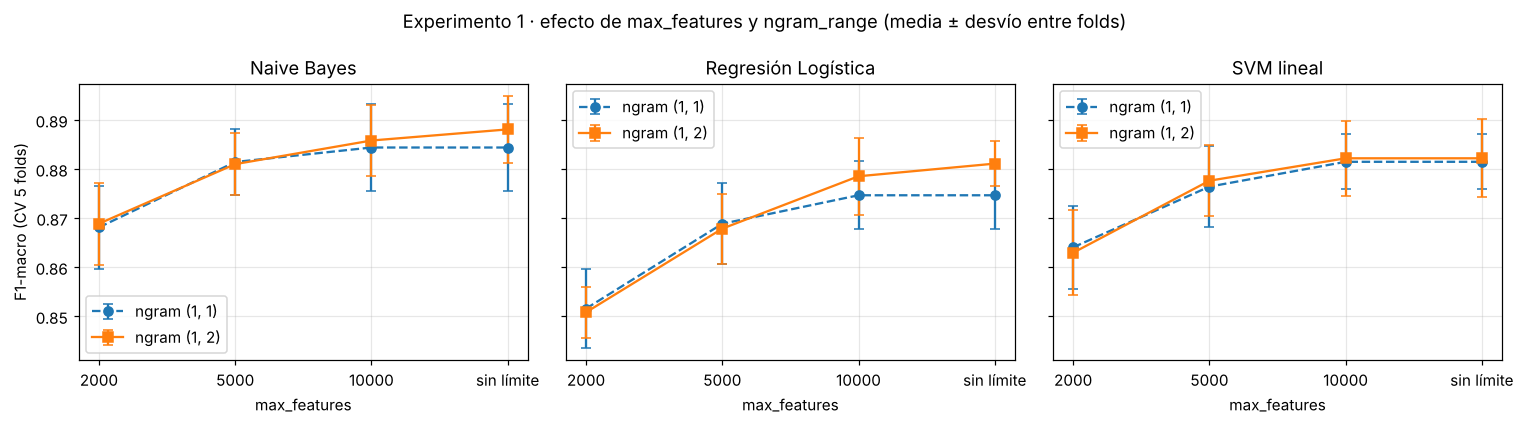

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), sharey=True)
orden_mf = ["2000", "5000", "10000", "sin límite"]
for ax, m in zip(axes, tb.MODELOS):
    for ng, estilo in [("(1, 1)", "o--"), ("(1, 2)", "s-")]:
        d = exp[(exp.modelo == m) & (exp.ngram_range == ng)].copy()
        d["mf"] = d.max_features.astype(str)
        d = d.set_index("mf").loc[orden_mf]
        ax.errorbar(orden_mf, d.f1_macro_cv, yerr=d.f1_std, fmt=estilo, capsize=3, label=f"ngram {ng}")
    ax.set(title=m, xlabel="max_features"); ax.legend()
axes[0].set_ylabel("F1-macro (CV 5 folds)")
fig.suptitle("Experimento 1 · efecto de max_features y ngram_range (media ± desvío entre folds)")
fig.tight_layout(); fig.savefig(tb.FIGURES / "experimento_max_features_ngram.png", dpi=150); plt.show()

In [9]:
# Efecto aislado de cada hiperparámetro, promediando sobre el resto
efecto_ng = exp.groupby(["modelo", "ngram_range"]).f1_macro_cv.max().unstack().round(4)
efecto_ng["mejora bigramas (pts)"] = ((efecto_ng["(1, 2)"] - efecto_ng["(1, 1)"]) * 100).round(2)
efecto_mf = exp.assign(mf=exp.max_features.astype(str)).groupby(["modelo", "mf"]).f1_macro_cv.max().unstack()[orden_mf].round(4)
display(efecto_ng); display(efecto_mf)

ngram_range,"(1, 1)","(1, 2)",mejora bigramas (pts)
modelo,,,
Naive Bayes,0.8844,0.8881,0.37
Regresión Logística,0.8747,0.8811,0.64
SVM lineal,0.8815,0.8822,0.07


mf,2000,5000,10000,sin límite
modelo,,,,
Naive Bayes,0.8689,0.8814,0.8858,0.8881
Regresión Logística,0.8516,0.8689,0.8785,0.8811
SVM lineal,0.8641,0.8776,0.8822,0.8822


**Lectura del experimento 1**
- **`max_features` es el parámetro que más pesa.** Limitar a 2.000 términos cuesta entre 1,8 y 2,9 puntos de F1 según el modelo, porque se pierden términos discriminativos de baja frecuencia (nombres de empresas, equipos, políticos). Desde 10.000 la curva ya está casi plana. En este corpus, limitar más el vocabulario no evita overfitting sino que hace perder señal; `min_df=2` ya cumple la función de filtrar ruido.
- **Los bigramas suman poco pero de forma consistente** cuando no se limita el vocabulario (+0,1 a +0,6 puntos según el modelo): capturan entidades como `oil price`, `prime minister` o `red sox`. Con un tope bajo de `max_features` compiten por el mismo cupo que los unigramas y pueden empeorar el resultado.
- **Los tres modelos quedan muy cerca** (diferencias menores a 1 punto, del orden de un desvío entre folds).

## 5. Experimento 2 · Regularización de cada modelo
Para comparar los modelos en igualdad de condiciones, tomamos la mejor configuración del vectorizador de cada uno y barremos su hiperparámetro de regularización: `alpha` (suavizado de Laplace) en Naive Bayes y `C` (inverso de la regularización) en Regresión Logística y SVM.

In [10]:
reg = tb.ajustar_regularizacion(train_df.text_nostop, train_df.label, exp)
mejor_por_modelo = reg.loc[reg.groupby("modelo").f1_macro_cv.idxmax()].sort_values("f1_macro_cv", ascending=False)
display(reg.pivot_table(index=["modelo", "parametro"], columns="valor", values="f1_macro_cv").round(4))
mejor_por_modelo.round(4)

,valor,0.01,0.05,0.10,0.25,0.30,0.50,1.00,2.00,5.00,10.00,30.00,100.00
modelo,parametro,,,,,,,,,,,,
Naive Bayes,alpha,0.8813,0.8867,0.8881,NaN,0.8885,NaN,0.8870,NaN,NaN,NaN,NaN,NaN
Regresión Logística,C,NaN,NaN,NaN,NaN,NaN,NaN,0.8823,NaN,0.8817,0.8811,0.8794,0.8763
SVM lineal,C,NaN,NaN,0.8827,0.8848,NaN,0.8822,0.8807,0.8772,NaN,NaN,NaN,NaN


,modelo,ngram_range,max_features,parametro,valor,f1_macro_cv,f1_std,accuracy_cv
3,Naive Bayes,"(1, 2)",sin límite,alpha,0.30,0.8885,0.0062,0.8888
11,SVM lineal,"(1, 2)",sin límite,C,0.25,0.8848,0.0083,0.8852
5,Regresión Logística,"(1, 2)",sin límite,C,1.00,0.8823,0.0092,0.8826


In [11]:
# Costo computacional de cada modelo con su mejor configuración (entrenar en train completo + predecir test)
costos = []
for _, f in mejor_por_modelo.iterrows():
    ng, mf = tb._parse(f)
    p = tb.construir_pipeline(f.modelo, mf, ng, {f.parametro: f.valor})
    t0 = time.time(); p.fit(train_df.text_nostop, train_df.label); t_fit = time.time() - t0
    t0 = time.time(); p.predict(test_df.text_nostop); t_pred = time.time() - t0
    costos.append(dict(modelo=f.modelo, f1_macro_cv=round(f.f1_macro_cv, 4), f1_std=round(f.f1_std, 4),
                       seg_entrenamiento=round(t_fit, 2), ms_por_noticia_pred=round(t_pred / len(test_df) * 1000, 3)))
costos = pd.DataFrame(costos); costos

,modelo,f1_macro_cv,f1_std,seg_entrenamiento,ms_por_noticia_pred
0,Naive Bayes,0.8885,0.0062,0.32,0.023
1,SVM lineal,0.8848,0.0083,0.37,0.021
2,Regresión Logística,0.8823,0.0092,0.67,0.023


**Elección del modelo: Multinomial Naive Bayes** (`alpha=0.3`, TF-IDF `(1, 2)`, sin límite de vocabulario).
- Tiene el **mejor F1-macro en CV** (0,8885). La diferencia con SVM (0,8848) y Regresión Logística (0,8823) es menor a un desvío entre folds, así que **los tres son estadísticamente equivalentes** en este corpus.
- A igualdad de desempeño, gana el más **simple y rápido**. Naive Bayes entrena en una sola pasada (cuenta frecuencias por clase), no tiene que converger y es el que menos tarda.
- Encaja con el problema: la teoría lo recomienda para documentos breves, y AG News tiene una mediana de 37 tokens.
- Es **interpretable**: `feature_log_prob_` dice qué términos pesan más en cada clase (sección 11).
- **SVM lineal queda como alternativa**, prácticamente empatada. Si en el Módulo 4 hace falta un baseline más fuerte frente a ruido, es la siguiente opción a probar.

## 6. Experimento 3 · Preprocesamiento: crudo vs. stemming vs. lematización
Mismo modelo y mismo vectorizador, cambiando solo la entrada: texto **crudo**, **stemming de Porter** (la función `limpiar_texto` del notebook de clase de clasificación de emociones), **solo limpieza regex** (`clean_text`) y el **pipeline completo del Módulo 2** (`text_nostop`, con lematización).

In [12]:
from src.text_preprocessing import clean_text
mejor = mejor_por_modelo.iloc[0]
NG, MF = tb._parse(mejor)
CLF_PARAMS = {mejor.parametro: mejor.valor}
import re as _re
import nltk
from nltk.corpus import stopwords as _sw
from nltk.stem import PorterStemmer
try:
    _sw.words("english")
except LookupError:
    nltk.download("stopwords", quiet=True)
_STOP_NLTK, _porter = set(_sw.words("english")), PorterStemmer()
def limpiar_con_stemming(texto):
    """Versión del notebook de clase (Clasificacion_Emociones): solo letras, minúsculas, stop-words de NLTK y stemming de Porter."""
    palabras = _re.sub("[^a-zA-Z]", " ", texto).lower().split()
    return " ".join(_porter.stem(p) for p in palabras if p not in _STOP_NLTK)

entradas = {
    "1. Texto crudo (tokenización por defecto de sklearn)": (train_df.text, dict(token_pattern=r"(?u)\b\w\w+\b", lowercase=True)),
    "1b. Stemming de Porter (función del notebook de clase)": (train_df.text.map(limpiar_con_stemming), {}),
    "1c. clean_text + stemming de Porter":                  (train_df.text.map(clean_text).map(limpiar_con_stemming), {}),
    "2. Solo limpieza regex (clean_text)":                  (train_df.text.map(clean_text), dict(token_pattern=r"(?u)\b\w\w+\b", lowercase=True)),
    "3. Pipeline completo M2 (lemas, sin stop-words)":      (train_df.text_nostop, {}),
}
from sklearn.model_selection import cross_validate
filas = []
for nombre, (X, extra) in entradas.items():
    p = tb.construir_pipeline(mejor.modelo, MF, NG, CLF_PARAMS, **extra)
    r = cross_validate(p, X, train_df.label, cv=tb._cv(), scoring="f1_macro", n_jobs=-1)
    v = len(tb.construir_pipeline(mejor.modelo, MF, NG, CLF_PARAMS, **extra).named_steps["tfidf"].fit(X).vocabulary_)
    filas.append(dict(entrada=nombre, vocabulario=v, f1_macro_cv=round(r["test_score"].mean(), 4), f1_std=round(r["test_score"].std(), 4)))
prep = pd.DataFrame(filas)
prep["mejora vs. crudo (pts)"] = ((prep.f1_macro_cv - prep.f1_macro_cv.iloc[0]) * 100).round(2)
prep

,entrada,vocabulario,f1_macro_cv,f1_std,mejora vs. crudo (pts)
0,1. Texto crudo (tokenización por defecto de sklearn),44194,0.8906,0.0053,0.00
1,1b. Stemming de Porter (función del notebook de clase),27245,0.8955,0.0049,0.49
2,1c. clean_text + stemming de Porter,26143,0.8890,0.0061,-0.16
3,2. Solo limpieza regex (clean_text),42662,0.8837,0.0051,-0.69
4,"3. Pipeline completo M2 (lemas, sin stop-words)",25780,0.8885,0.0062,-0.21


In [13]:
# Términos más distintivos de Business según cada entrada (mismo modelo y vectorizador)
def top_distintivos(X, clase="Business", k=8, **extra):
    p = tb.construir_pipeline(mejor.modelo, MF, NG, CLF_PARAMS, **extra).fit(X, train_df.label)
    v = p.named_steps["tfidf"].get_feature_names_out(); lp = p.named_steps["clf"].feature_log_prob_
    j = list(p.classes_).index(clase)
    return ", ".join(v[i] for i in np.argsort(lp[j] - np.delete(lp, j, axis=0).mean(axis=0))[::-1][:k])
pd.Series({nombre: top_distintivos(X, **extra) for nombre, (X, extra) in entradas.items()}, name="top términos distintivos de Business").to_frame()

,top términos distintivos de Business
1. Texto crudo (tokenización por defecto de sklearn),"fullquote, investor reuters, aspx ticker, fullquote aspx, reuters com, www investor, com fullquote, quickinfo"
1b. Stemming de Porter (función del notebook de clase),"fullquot, investor reuter, target stock, quickinfo fullquot, stock quickinfo, quickinfo, fullquot aspx, aspx"
1c. clean_text + stemming de Porter,"oil price, insur, profit, inc, oil, crude, treasuri, us airway"
2. Solo limpieza regex (clean_text),"oil prices, insurance, stocks, oil, inc, profit, prices, crude"
"3. Pipeline completo M2 (lemas, sin stop-words)","oil price, insurance, inc, profit, oil, u.s airways, treasury, crude"


In [14]:
# ¿Qué aprende el modelo entrenado con texto crudo? Términos más distintivos de cada clase
p_crudo = tb.construir_pipeline(mejor.modelo, MF, NG, CLF_PARAMS, token_pattern=r"(?u)\b\w\w+\b", lowercase=True).fit(train_df.text, train_df.label)
v_c = p_crudo.named_steps["tfidf"].get_feature_names_out(); lp_c = p_crudo.named_steps["clf"].feature_log_prob_
pd.DataFrame({c: [v_c[i] for i in np.argsort(lp_c[j] - np.delete(lp_c, j, axis=0).mean(axis=0))[::-1][:10]]
              for j, c in enumerate(p_crudo.named_steps["clf"].classes_)})

,Business,Sci_Tech,Sports,World
0,fullquote,nasa,league,palestinian
1,investor reuters,microsoft,coach,baghdad
2,aspx ticker,users,cup,gaza
3,fullquote aspx,space,football,troops
4,reuters com,software,sports network,iraq
5,www investor,scientists,championship,militants
6,com fullquote,linux,nfl,darfur
7,quickinfo,apple,champions,arafat
8,aspx,windows,world cup,sudan
9,quickinfo fullquote,open source,quarterback,hostage


In [15]:
# Las firmas de agencia y los links están correlacionados con la clase: un atajo, no contenido
agencias = {"(Reuters)": r"\(Reuters\)", "(AP) / AP -": r"\(AP\)|\bAP -", "(AFP) / AFP -": r"\(AFP\)|AFP -", "link Quote, Profile, Research": r"Quote, Profile"}
pd.DataFrame({k: train_df.label[train_df.text.str.contains(p)].value_counts(normalize=True).reindex(tb.CLASES).fillna(0)
              for k, p in agencias.items()}).T.mul(100).round(0).astype(int).astype(str).add("%")

label,Business,Sci_Tech,Sports,World
(Reuters),46%,15%,11%,28%
(AP) / AP -,3%,26%,36%,35%
(AFP) / AFP -,12%,6%,8%,74%
"link Quote, Profile, Research",91%,9%,0%,0%


**Lectura del experimento 3: el texto crudo "gana" por un atajo**
- Con texto crudo el F1 en CV es apenas mayor (+0,2 puntos, dentro de un desvío entre folds). La tabla de arriba muestra por qué: **los términos más distintivos de Business en el modelo crudo son fragmentos de URL** (`fullquote`, `investor reuters`, `aspx ticker`), los restos del link de cotizaciones de Reuters. Además, la agencia funciona como pista de la clase: AFP aparece en un 74% de noticias World y AP casi nunca en Business (3%).
- Es un caso típico de **shortcut learning**: el modelo aprende quién escribió el cable, no de qué trata la noticia. Esa señal no serviría con noticias de otras fuentes ni en producción. Al quitarla, la limpieza regex sola baja el F1 (−0,7 puntos), y la **lematización + stop-words recupera casi todo** (−0,2 puntos frente al crudo, empate estadístico).
- **Stemming vs. lematización:** el stemming de Porter (`limpiar_texto` del notebook de clase) aplicado sobre el texto crudo da el F1 más alto de la tabla. Pero cae en **el mismo atajo**: como solo borra lo que no es letra, conserva los restos de URLs, y sus términos más distintivos de Business vuelven a ser `fullquot`, `investor reuter` y `quickinfo` (ver la celda siguiente). Si primero se aplica la limpieza estructural (fila 1c), **stemming y lematización quedan empatados** (0,8890 vs. 0,8885). La diferencia la hace la limpieza, no la forma de normalizar. Se prefiere la lematización porque produce palabras reales (`company`, `insurance`) en vez de raíces truncadas (`compani`, `insur`), que se pueden interpretar.
- **Decisión: se mantiene el pipeline del Módulo 2.** Logra un desempeño equivalente con un **vocabulario 42% más chico** (25.780 vs. 44.194 términos) y con todos los términos distintivos sobre el contenido real (`nasa`, `oil price`, `quarterback`, `gaza`, ver sección 11).

## 7. Experimento 4 · CountVectorizer (BoW) vs. TfidfVectorizer
Como en el notebook de clase, comparamos las dos representaciones con varios clasificadores, sumando **Random Forest** (no lineal). Mismas condiciones: `ngram_range=(1, 2)`, sin límite de vocabulario, `min_df=2`, CV de 5 folds sobre train.

In [16]:
t0 = time.time()
filas = []
for m in ["Naive Bayes", "Regresión Logística", "SVM lineal", "Random Forest"]:
    for v, nombre_v in [("bow", "CountVectorizer (BoW)"), ("tfidf", "TfidfVectorizer")]:
        p = tb.construir_pipeline(m, None, (1, 2), vectorizador=v)
        r = cross_validate(p, train_df.text_nostop, train_df.label, cv=tb._cv(), scoring="f1_macro",
                           n_jobs=1 if m == "Random Forest" else -1)
        filas.append(dict(modelo=m, vectorizador=nombre_v, f1_macro_cv=r["test_score"].mean(), f1_std=r["test_score"].std(),
                          seg_por_fold=np.mean(r["fit_time"])))
bow_vs_tfidf = pd.DataFrame(filas)
print(f"8 combinaciones × 5 folds en {time.time() - t0:.0f} s")
display(bow_vs_tfidf.pivot(index="modelo", columns="vectorizador", values="seg_por_fold").round(2).add_prefix("seg_por_fold · "))
tabla_bt = bow_vs_tfidf.pivot(index="modelo", columns="vectorizador", values="f1_macro_cv")
tabla_bt["mejora TF-IDF (pts)"] = ((tabla_bt["TfidfVectorizer"] - tabla_bt["CountVectorizer (BoW)"]) * 100).round(2)
tabla_bt.round(4).sort_values("TfidfVectorizer", ascending=False)

8 combinaciones × 5 folds en 81 s


vectorizador,seg_por_fold · CountVectorizer (BoW),seg_por_fold · TfidfVectorizer
modelo,,
Naive Bayes,0.26,0.25
Random Forest,7.42,6.76
Regresión Logística,0.45,0.79
SVM lineal,0.50,0.27


vectorizador,CountVectorizer (BoW),TfidfVectorizer,mejora TF-IDF (pts)
modelo,,,
Naive Bayes,0.8853,0.8881,0.28
SVM lineal,0.8584,0.8822,2.38
Regresión Logística,0.8657,0.8811,1.54
Random Forest,0.8419,0.8438,0.19


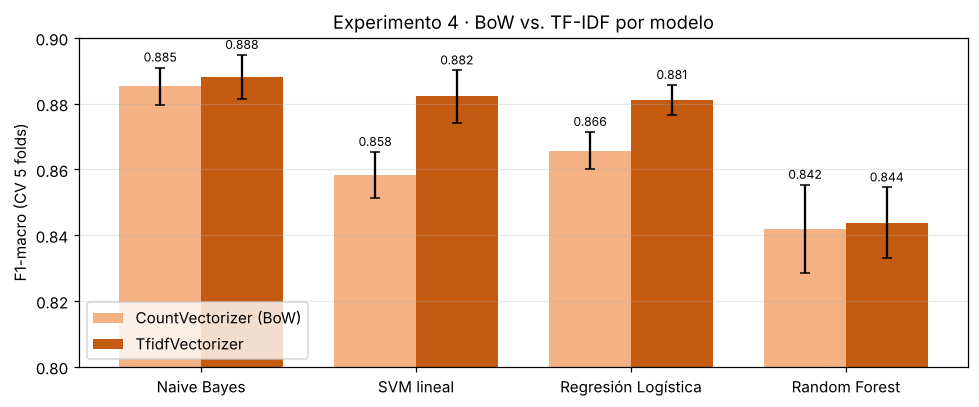

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.8))
orden_m = tabla_bt.sort_values("TfidfVectorizer", ascending=False).index
x = np.arange(len(orden_m)); w = 0.38
for k, (col, color) in enumerate([("CountVectorizer (BoW)", "#f4b183"), ("TfidfVectorizer", "#c55a11")]):
    d = bow_vs_tfidf[bow_vs_tfidf.vectorizador == col].set_index("modelo").loc[orden_m]
    b = ax.bar(x + (k - .5) * w, d.f1_macro_cv, w, yerr=d.f1_std, capsize=3, color=color, label=col)
    ax.bar_label(b, fmt="%.3f", padding=2, fontsize=8)
ax.set_xticks(x, orden_m); ax.set_ylim(0.80, 0.90); ax.set_ylabel("F1-macro (CV 5 folds)")
ax.set_title("Experimento 4 · BoW vs. TF-IDF por modelo"); ax.legend(loc="lower left"); ax.grid(axis="x")
fig.tight_layout(); fig.savefig(tb.FIGURES / "bow_vs_tfidf.png", dpi=150); plt.show()

**Lectura del experimento 4**
- **TF-IDF iguala o supera a BoW en todos los modelos.** La mejora es mayor en los **modelos lineales** (Regresión Logística y SVM), como anticipa la teoría: la norma L2 pone a todos los documentos en la misma escala y facilita la optimización. En Naive Bayes la diferencia es chica, porque el modelo fue pensado para conteos.
- **Random Forest queda último** (unos 4,4 puntos abajo) y es decenas de veces más lento (ver `seg_por_fold`). Con 25.780 columnas esparsas, cada árbol ve pocas palabras por división y no aprovecha la señal repartida en miles de términos. Por eso los clasificadores lineales son el estándar para texto vectorizado.

## 8. Modelo final: entrenamiento en train y evaluación única en test

In [18]:
from sklearn.metrics import classification_report, accuracy_score, f1_score
final = tb.construir_pipeline(mejor.modelo, MF, NG, CLF_PARAMS)
final.fit(train_df.text_nostop, train_df.label)          # fit_transform del TF-IDF + entrenamiento: SOLO train
pred = final.predict(test_df.text_nostop)                # transform del TF-IDF + predicción: test
print(final, "\n")
print(classification_report(test_df.label, pred, digits=3))
acc, f1m = accuracy_score(test_df.label, pred), f1_score(test_df.label, pred, average="macro")
print(f"Test -> accuracy {acc:.4f} | F1-macro {f1m:.4f} | F1-macro en CV {mejor.f1_macro_cv:.4f} "
      f"(diferencia {abs(f1m - mejor.f1_macro_cv) * 100:.2f} pts)")

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(lowercase=False, max_df=0.95, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True,
                                 token_pattern='\\S+')),
                ('clf', MultinomialNB(alpha=np.float64(0.3)))]) 

              precision    recall  f1-score   support

    Business      0.835     0.862     0.848       500
    Sci_Tech      0.870     0.870     0.870       500
      Sports      0.955     0.968     0.961       500
       World      0.910     0.868     0.888       500

    accuracy                          0.892      2000
   macro avg      0.892     0.892     0.892      2000
weighted avg      0.892     0.892     0.892      2000

Test -> accuracy 0.8920 | F1-macro 0.8920 | F1-macro en CV 0.8885 (diferencia 0.36 pts)


La métrica en test (0,892) es **consistente con la de CV** (0,8885): el modelo generaliza y la estimación no está inflada. Esto es lo esperable cuando no hay fuga de datos.

## 9. Matriz de confusión y análisis de errores

In [19]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(test_df.label, pred, labels=tb.CLASES)
fig = tb.graficar_confusion(cm, tb.FIGURES / "matriz_confusion.png",
                            f"Naive Bayes · TF-IDF (1, 2) · alpha={mejor.valor} · test (n = 2.000)")
plt.show()

In [20]:
pares = (pd.DataFrame(cm, index=tb.CLASES, columns=tb.CLASES).stack().rename("errores").reset_index()
         .rename(columns={"level_0": "real", "level_1": "predicha"}))
pares = pares[pares.real != pares.predicha].sort_values("errores", ascending=False).head(6)
pares["% de la clase real"] = (pares.errores / 500 * 100).round(1)
pares

,real,predicha,errores,% de la clase real
4,Sci_Tech,Business,45,9.0
1,Business,Sci_Tech,39,7.8
12,World,Business,36,7.2
3,Business,World,25,5.0
13,World,Sci_Tech,16,3.2
7,Sci_Tech,World,16,3.2


In [21]:
errores = test_df.assign(pred=pred)[test_df.label != pred]
ejemplos = errores[((errores.label == "Business") & (errores.pred == "Sci_Tech")) |
                   ((errores.label == "Sci_Tech") & (errores.pred == "Business")) |
                   ((errores.label == "World") & (errores.pred == "Business"))].groupby(["label", "pred"]).head(2)
ejemplos[["label", "pred", "text"]].assign(text=lambda d: d.text.str[:170])

,label,pred,text
0,World,Business,BSkyB sees profits rise after strong subscriber growth (AFP). AFP - British satellite broadcaster BSkyB said profit rose by 16 percent in the first quarter ...
7,World,Business,Producer sues for Rings profits. Hollywood producer Saul Zaentz sues the producers of The Lord of the Rings for $20m in royalties.
45,Sci_Tech,Business,E.U. Regulators Approve Oracle's PeopleSoft Bid. European Union antitrust regulators on Tuesday cleared Oracle Corp.'s hostile $7.7 billion bid for rival bu...
47,Sci_Tech,Business,"Make hotels just like home. HOTEL operators, take note: Todays hotel guests are making a nonsense of room-pricing strategies with their aggressive, Internet..."
107,Business,Sci_Tech,"Symantec Said to Be in Talks for Veritas. Symantec, which produces the Norton line of computer products, is in talks to acquire Veritas Software, a maker of..."
149,Business,Sci_Tech,"Med school move delayed to 2007. The MSU College of Human Medicine won #39;t be relocated to Grand Rapids until at least 2007, and could cost only half as m..."


**Categorías más difíciles**
1. **Business y Sci_Tech** son las clases con menor F1 (0,85 y 0,87), y **el par que más se confunde es Business ↔ Sci_Tech**. Las noticias sobre empresas tecnológicas (resultados de Microsoft, fusiones de telecomunicaciones, precios de chips) usan vocabulario de ambas clases, y una bolsa de palabras no puede decidir si el foco es el negocio o la tecnología.
2. **World → Business** es la segunda fuente de error: noticias de economía internacional (petróleo, comercio, monedas) que la cátedra etiquetó como World.
3. **Sports** es la clase más fácil (F1 0,96), porque su vocabulario es casi exclusivo (equipos, jugadores, resultados).

Estas confusiones son **semánticas, no de ruido**: el modelo necesita contexto para desambiguarlas. Es justo la limitación de TF-IDF que debería resolver el Transformer del Módulo 4.

## 10. Métricas para texto: promedios del F1 y curvas Precision-Recall
Como se vio en clase, el accuracy puede engañar ("cuando 99% no significa nada"), y el F1 se puede promediar de tres formas:
- **Macro:** promedio simple por clase. Todas pesan igual y revela problemas en las clases chicas.
- **Weighted:** pondera por cantidad de ejemplos. Puede esconder una clase minoritaria floja.
- **Micro:** suma aciertos globales. En multiclase con una etiqueta por documento equivale al accuracy.

In [22]:
from sklearn.metrics import precision_recall_fscore_support
promedios = pd.DataFrame({avg: precision_recall_fscore_support(test_df.label, pred, average=avg)[:3]
                          for avg in ["macro", "weighted", "micro"]}, index=["precision", "recall", "F1"]).T.round(4)
promedios["accuracy"] = round(acc, 4)
promedios

,precision,recall,F1,accuracy
macro,0.8924,0.892,0.892,0.892
weighted,0.8924,0.892,0.892,0.892
micro,0.8920,0.892,0.892,0.892


Con AG News **los tres promedios coinciden**, porque el corpus está perfectamente balanceado (500 noticias por clase en test). Por eso el accuracy no engaña en este caso. Igual reportamos F1-macro, que es la métrica correcta si en el Proyecto Final el corpus llegara a tener desbalance.

In [23]:
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
proba = final.predict_proba(test_df.text_nostop)
Y = label_binarize(test_df.label, classes=final.classes_)
fig, ax = plt.subplots(figsize=(7, 5))
ap = {}
for j, c in enumerate(final.classes_):
    prec, rec, _ = precision_recall_curve(Y[:, j], proba[:, j])
    ap[c] = average_precision_score(Y[:, j], proba[:, j])
    ax.plot(rec, prec, lw=2, label=f"{c} (PR-AUC = {ap[c]:.3f})")
ax.axhline(0.25, color="gray", ls=":", label="azar (prevalencia 25%)")
ax.set(xlabel="Recall", ylabel="Precision", title="Curvas Precision-Recall por clase (one-vs-rest, test)", xlim=(0, 1.01), ylim=(0, 1.02))
ax.legend(loc="lower left"); fig.tight_layout(); fig.savefig(tb.FIGURES / "curvas_precision_recall.png", dpi=150); plt.show()
pd.Series(ap, name="PR-AUC").round(4).to_frame()

,PR-AUC
Business,0.8776
Sci_Tech,0.9318
Sports,0.9734
World,0.9399


In [24]:
# ¿Dónde poner el umbral? Ejemplo con Business: subir el umbral gana precisión a costa de recall
prec, rec, thr = precision_recall_curve(Y[:, 0], proba[:, 0])
umbrales = pd.DataFrame({"umbral": thr, "precision": prec[:-1], "recall": rec[:-1]})
umbrales.iloc[[umbrales.umbral.sub(u).abs().idxmin() for u in [0.3, 0.5, 0.7, 0.9]]].round(3).set_index("umbral")

,precision,recall
umbral,,
0.296,0.799,0.898
0.505,0.855,0.834
0.701,0.904,0.750
0.900,0.924,0.488


**Lectura**
- Las curvas P-R confirman la matriz: **Sports** tiene el PR-AUC más alto (0,973) y **Business** el más bajo (0,878), lejos del resto, porque es la clase que más se mezcla con Sci_Tech y con World.
- **El umbral es una decisión de negocio.** Por defecto se elige la clase con mayor probabilidad, pero si el costo de los errores no es simétrico conviene moverlo. En la tabla de Business: con umbral 0,5 la precisión es 0,855 y el recall 0,834. Subirlo a 0,9 lleva la precisión a 0,924, pero el recall cae a 0,488, porque se pierde la mitad de las noticias. Bajarlo a 0,3 da recall 0,898 con precisión 0,799.

## 11. Interpretabilidad: términos con más peso por clase
Para Naive Bayes usamos `feature_log_prob_`: la probabilidad (en logaritmo) de cada término dada la clase.

In [25]:
tb.top_terminos(final, k=12)

,Business,Sci_Tech,Sports,World
0,u.s,microsoft,win,kill
1,oil,new,game,iraq
2,price,software,season,president
3,company,internet,team,u.s
4,inc,company,night,minister
5,profit,service,cup,election
6,stock,computer,league,leader
7,rise,space,victory,official
8,percent,year,year,government
9,share,technology,world,people


In [26]:
# Términos con más peso RELATIVO: log P(t|clase) - promedio de log P(t|otras clases). Muestra qué distingue a cada clase.
vocab = final.named_steps["tfidf"].get_feature_names_out()
lp = final.named_steps["clf"].feature_log_prob_
clases = final.named_steps["clf"].classes_
distintivos = {c: [vocab[i] for i in np.argsort(lp[j] - np.delete(lp, j, axis=0).mean(axis=0))[::-1][:10]] for j, c in enumerate(clases)}
pd.DataFrame(distintivos)

,Business,Sci_Tech,Sports,World
0,oil price,nasa,league,militant
1,insurance,user,coach,palestinian
2,inc,microsoft,cup,hostage
3,profit,server,football,troop
4,oil,scientist,championship,baghdad
5,u.s airways,linux,0,gaza
6,treasury,software,nfl,arafat
7,crude,open source,champion,darfur
8,airways,apple,quarterback,soldier
9,quarterly,space,tournament,sudan


## 12. Uso del modelo: guardar, cargar y predecir titulares nuevos
Como en el notebook de clase (`predict_emotion` + `pickle`), dejamos el modelo listo para usar. Se guarda **el `Pipeline` completo** (vectorizador + clasificador) en un solo archivo con `joblib`, que es la forma recomendada por scikit-learn. Así es imposible usar el modelo con un vectorizador distinto del que se entrenó. `predecir_categoria()` aplica a cualquier texto nuevo **el mismo preprocesamiento del Módulo 2**.

In [27]:
ruta = tb.guardar_modelo(final)
print(f"Modelo guardado en {ruta.relative_to(ROOT)} ({ruta.stat().st_size / 1e6:.1f} MB)")
modelo_cargado = tb.cargar_modelo()
print("Mismas predicciones que el modelo en memoria:", (modelo_cargado.predict(test_df.text_nostop) == pred).all())

titulares = [
    "Apple unveils new iPhone with faster chip and better battery",
    "Oil prices jump as OPEC agrees to cut output",
    "Messi scores twice as Barcelona beats Real Madrid",
    "UN warns of humanitarian crisis in Sudan as fighting spreads",
    "Microsoft shares fall after cloud revenue misses estimates",   # ambiguo: Business o Sci_Tech
    "Government announces new tax on tech companies",              # ambiguo: World, Business o Sci_Tech
]
tb.predecir_categoria(titulares, modelo_cargado)

Modelo guardado en models/clasificador_tfidf_nb.joblib (1.0 MB)
Mismas predicciones que el modelo en memoria: True


,texto,categoria,Business,Sci_Tech,Sports,World
0,Apple unveils new iPhone with faster chip and better battery,Sci_Tech,0.090,0.888,0.012,0.009
1,Oil prices jump as OPEC agrees to cut output,Business,0.992,0.002,0.001,0.006
2,Messi scores twice as Barcelona beats Real Madrid,Sports,0.004,0.009,0.982,0.006
3,UN warns of humanitarian crisis in Sudan as fighting spreads,World,0.013,0.018,0.006,0.963
4,Microsoft shares fall after cloud revenue misses estimates,Business,0.815,0.152,0.017,0.017
5,Government announces new tax on tech companies,Business,0.472,0.375,0.020,0.133


Los cuatro primeros titulares son claros y el modelo los acierta con 89% a 99% de probabilidad. Los dos últimos son **ambiguos a propósito**. La noticia sobre las acciones de Microsoft va a Business (82%), pero le asigna 15% a Sci_Tech. La del impuesto a las tecnológicas reparte la probabilidad entre Business (47%), Sci_Tech (38%) y World (13%). Es la misma confusión que muestra la matriz.

## 13. Exploración no supervisada: tópicos con LDA vs. categorías reales
¿Qué pasaría si no tuviéramos etiquetas? Con LDA (el algoritmo de tópicos de la clase) buscamos 4 temas en el train **sin mirar `label`**, y después los cruzamos con las categorías reales. LDA trabaja sobre **conteos**, así que usa `CountVectorizer`.

In [28]:
from sklearn.decomposition import LatentDirichletAllocation
cv_lda = CountVectorizer(token_pattern=r"\S+", min_df=5, max_df=0.5, max_features=5000)
X_lda = cv_lda.fit_transform(train_df.text_nostop)
lda = LatentDirichletAllocation(n_components=4, learning_method="batch", max_iter=25, random_state=tb.SEED).fit(X_lda)
voc = cv_lda.get_feature_names_out()
topicos = pd.DataFrame({f"Tópico {k}": [voc[i] for i in comp.argsort()[::-1][:10]] for k, comp in enumerate(lda.components_)})
display(topicos)
asignado = lda.transform(X_lda).argmax(axis=1)
cruce = pd.crosstab(pd.Series(asignado, name="tópico LDA").map(lambda k: f"Tópico {k}"), train_df.label, normalize="index").mul(100).round(0)
cruce

,Tópico 0,Tópico 1,Tópico 2,Tópico 3
0,win,company,u.s,game
1,world,new,president,year
2,cup,u.s,kill,season
3,open,price,iraq,new
4,final,inc,official,win
5,u.s,microsoft,government,night
6,olympic,oil,people,not
7,6,year,bush,run
8,test,corp,court,red
9,team,share,minister,no


label,Business,Sci_Tech,Sports,World
tópico LDA,,,,
Tópico 0,2.0,5.0,75.0,18.0
Tópico 1,51.0,45.0,1.0,3.0
Tópico 2,16.0,11.0,3.0,69.0
Tópico 3,3.0,19.0,67.0,11.0


In [29]:
from sklearn.metrics import adjusted_rand_score
pureza = cruce.max(axis=1).mean()
print(f"Pureza media de los tópicos: {pureza:.0f}% | Adjusted Rand Index vs. etiquetas: {adjusted_rand_score(train_df.label, asignado):.3f}")

Pureza media de los tópicos: 66% | Adjusted Rand Index vs. etiquetas: 0.353


**Lectura:** sin ver ninguna etiqueta, LDA recupera temas que se parecen a las categorías. Dos tópicos son de deportes (75% y 67% Sports) y uno de política y conflicto (69% World). En cambio, Business y Sci_Tech quedan **fusionadas en un mismo tópico** (51% / 45%), la misma frontera difusa que muestra la matriz de confusión del modelo supervisado. La pureza media es 66% y el ARI 0,35. La pureza muestra que la estructura temática existe en los datos. También que **el aprendizaje supervisado agrega mucho**: con etiquetas pasamos a 89% de aciertos. Fuera de este caso, LDA sirve cuando no hay etiquetas (por ejemplo, para descubrir de qué se quejan los clientes) y el nombre de cada tópico lo pone el analista.

## 14. Tabla esperado vs. observado

In [30]:
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="most_frequent").fit(train_df.text_nostop, train_df.label)
f1_dummy = f1_score(test_df.label, dummy.predict(test_df.text_nostop), average="macro")
acc_dummy = accuracy_score(test_df.label, dummy.predict(test_df.text_nostop))
tabla = pd.DataFrame([
    ["Pipeline corre de punta a punta", "sin errores", "OK (este notebook y `python -m src.train_baseline`)"],
    ["Sin solapamiento train/test", "0 textos de test en train", str(tb.validar(train_df, test_df).loc["test", "test_en_train"])],
    ["Vocabulario aprendido solo con train", "0 términos exclusivos de test en el vocabulario", str(sum(t in vocab_set for t in solo_test)) if (vocab_set := set(final.named_steps['tfidf'].vocabulary_)) else ""],
    ["Bigramas mejoran sin tope de vocabulario", "F1 (1,2) > F1 (1,1)", f"{efecto_ng['mejora bigramas (pts)'].min():+.2f} a {efecto_ng['mejora bigramas (pts)'].max():+.2f} pts"],
    ["max_features bajo pierde señal", "F1(2000) < F1(sin límite)", f"−{(efecto_mf['sin límite'] - efecto_mf['2000']).min()*100:.1f} a −{(efecto_mf['sin límite'] - efecto_mf['2000']).max()*100:.1f} pts"],
    ["Preprocesamiento M2 vs. texto crudo", "F1 equivalente (|Δ| < 1 desvío) con menos vocabulario", f"{prep['mejora vs. crudo (pts)'].iloc[-1]:+.2f} pts (desvío ±{prep.f1_std.iloc[-1]*100:.2f}); vocabulario {prep.vocabulario.iloc[-1]:,} vs {prep.vocabulario.iloc[0]:,}"],
    ["Baseline supera al clasificador trivial", "F1-macro ≫ dummy", f"{f1m:.3f} vs {f1_dummy:.3f} (accuracy dummy {acc_dummy:.2f})"],
    ["Stemming vs. lematización (con limpieza previa)", "F1 equivalente", f"{prep.f1_macro_cv.iloc[2]:.4f} vs {prep.f1_macro_cv.iloc[-1]:.4f}"],
    ["TF-IDF vs. BoW (CountVectorizer)", "TF-IDF ≥ BoW en todos los modelos", f"{tabla_bt['mejora TF-IDF (pts)'].min():+.2f} a {tabla_bt['mejora TF-IDF (pts)'].max():+.2f} pts"],
    ["Modelos lineales vs. Random Forest", "lineales > RF en texto esparso", f"RF {tabla_bt.loc['Random Forest', 'TfidfVectorizer']:.3f} vs NB {tabla_bt.loc['Naive Bayes', 'TfidfVectorizer']:.3f}"],
    ["F1 macro = weighted = micro", "iguales (clases balanceadas)", " / ".join(f"{v:.3f}" for v in promedios.F1)],
    ["Modelo guardado = modelo en memoria", "mismas predicciones", str(bool((modelo_cargado.predict(test_df.text_nostop) == pred).all()))],
    ["Test consistente con CV", "diferencia < 1 pt", f"{abs(f1m - mejor.f1_macro_cv) * 100:.2f} pts"],
    ["Clase más fácil / más difícil", "Sports / Business", f"{pd.Series(f1_score(test_df.label, pred, average=None, labels=tb.CLASES), index=tb.CLASES).idxmax()} / {pd.Series(f1_score(test_df.label, pred, average=None, labels=tb.CLASES), index=tb.CLASES).idxmin()}"],
], columns=["Prueba", "Esperado", "Observado"])
tabla

,Prueba,Esperado,Observado
0,Pipeline corre de punta a punta,sin errores,OK (este notebook y `python -m src.train_baseline`)
1,Sin solapamiento train/test,0 textos de test en train,0
2,Vocabulario aprendido solo con train,0 términos exclusivos de test en el vocabulario,0
3,Bigramas mejoran sin tope de vocabulario,"F1 (1,2) > F1 (1,1)",+0.07 a +0.64 pts
4,max_features bajo pierde señal,F1(2000) < F1(sin límite),−1.8 a −2.9 pts
5,Preprocesamiento M2 vs. texto crudo,F1 equivalente (|Δ| < 1 desvío) con menos vocabulario,"-0.21 pts (desvío ±0.62); vocabulario 25,780 vs 44,194"
6,Baseline supera al clasificador trivial,F1-macro ≫ dummy,0.892 vs 0.100 (accuracy dummy 0.25)
7,Stemming vs. lematización (con limpieza previa),F1 equivalente,0.8890 vs 0.8885
8,TF-IDF vs. BoW (CountVectorizer),TF-IDF ≥ BoW en todos los modelos,+0.19 a +2.38 pts
9,Modelos lineales vs. Random Forest,lineales > RF en texto esparso,RF 0.844 vs NB 0.888


## Conclusiones
- **El pipeline completo funciona:** del texto crudo a la predicción, con el preprocesamiento del Módulo 2, TF-IDF y Naive Bayes, sin fuga de datos (vectorizador dentro del `Pipeline`, ajustado solo con train).
- **Baseline: F1-macro 0,892 en test**, frente a 0,10 del clasificador trivial (accuracy 0,25), y consistente con la CV (0,8885).
- **Preprocesamiento:** con texto crudo el modelo obtiene el mismo F1, pero apoyándose en restos de URLs y firmas de agencia (*shortcut learning*). El pipeline del Módulo 2 logra un desempeño equivalente con 42% menos vocabulario y aprendiendo del contenido real.
- **Experimentación:** `max_features` es el hiperparámetro decisivo; recortar a 2.000 términos cuesta entre 1,8 y 2,9 puntos. Los bigramas suman alrededor de medio punto sin tope de vocabulario. Los tres modelos rinden prácticamente igual, y se eligió Naive Bayes por ser el mejor en CV, el más rápido y el más simple.
- **Stemming vs. lematización:** el stemming del notebook de clase parece mejor sobre texto crudo, pero también aprovecha los restos de URLs. Con limpieza previa, los dos empatan.
- **BoW vs. TF-IDF:** TF-IDF iguala o mejora a CountVectorizer en todos los modelos, sobre todo en los lineales, y Random Forest queda claramente detrás en texto esparso.
- **Evaluación:** F1 macro, weighted y micro coinciden porque el corpus está balanceado. Las curvas Precision-Recall confirman a Sports como la clase más separable y a Business / Sci_Tech como las más difíciles.
- **Listo para usar:** el `Pipeline` completo queda guardado (`models/clasificador_tfidf_nb.joblib`), y `predecir_categoria()` clasifica cualquier titular nuevo con el mismo preprocesamiento.
- **Errores:** se concentran en **Business ↔ Sci_Tech** (noticias de empresas tecnológicas) y en **World → Business** (economía internacional). Son ambigüedades de contexto que TF-IDF no puede resolver, y son el punto de partida para medir cuánto mejora el Transformer del Módulo 4.